In [1]:
#manipulação de dados
import pandas as pd
import numpy as np

#deepcopy
from copy import deepcopy

#modelos que iremos aplicar nos dados
from xgboost import XGBClassifier

#obtenção do grid e randomized search
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import roc_curve, auc

#visualização de dados
import plotly.express as px
import plotly.graph_objects as go
import seaborn as sns
import matplotlib.pyplot as plt

#seleção das variáveis
from boruta import BorutaPy

#importancia das variaveis
import shap

#definição de seed para reprodutibilidade
seed = 42

In [2]:
#Import da base de treino e teste
df_train = pd.read_csv("../datasets/dados_treino.csv",
                        encoding='latin1', sep=",")
df_test = pd.read_csv("../datasets/dados_teste.csv",
                        encoding='latin1', sep=",")
#Separação das bases entre X_train, X_test, y_train, y_test
X_train = df_train.drop(columns = "obito")
y_train = df_train.obito

X_test = df_test.drop(columns = "obito")
y_test = df_test.obito

y_train.value_counts(normalize = True)

obito
0.0    0.843917
1.0    0.156083
Name: proportion, dtype: float64

In [3]:
# Modelo e dicionário de busca
xgb = XGBClassifier(
    objective='binary:logistic',  # problema de classificação binária
    random_state=seed
    )

xgb_dict = {
    'n_estimators': np.arange(200, 501, 100),           # número de árvores, de 100 a 500 com passo de 100
    'max_depth': np.arange(3, 11, 1),                   # profundidade máxima da árvore, de 3 a 10
    'learning_rate': np.logspace(-2, -0.7, 4),          # taxa de aprendizado, de 0.01 a 0.2 em escala logarítmica
    'subsample': np.linspace(0.6, 1.0, 3),              # proporção de amostras usadas por árvore
    'colsample_bytree': np.linspace(0.6, 1.0, 3),       # proporção de features usadas por árvore
    'gamma': np.linspace(0, 0.3, 4),                    # regularização por redução mínima da perda
    'reg_alpha': np.logspace(-3, 0, 4),                 # regularização L1, de 0.001 a 1
    'reg_lambda': np.linspace(1, 2, 3)                  # regularização L2, de 1 a 2
}

# Criação do random search
xgb_rs = RandomizedSearchCV(
    estimator=xgb,
    param_distributions=xgb_dict,
    n_iter=20,              # número de combinações testadas
    scoring='roc_auc',      # métrica de avaliação
    cv=5,                   # validação cruzada 5-fold
    random_state=seed,      # seed para garantir reprodutibilidade
    n_jobs=-1               # usar todos os núcleos
)

# Fit do random search
xgb_rs.fit(X_train, y_train)

# Print dos melhores hiperparâmetros
print("Hiperparâmetros do xgb: ", xgb_rs.best_params_)
print("Score na base de treino: ", xgb_rs.best_score_)

# Criação do modelo final
xgb = xgb_rs.best_estimator_

Hiperparâmetros do xgb:  {'subsample': np.float64(0.8), 'reg_lambda': np.float64(2.0), 'reg_alpha': np.float64(1.0), 'n_estimators': np.int64(500), 'max_depth': np.int64(3), 'learning_rate': np.float64(0.02712272579332028), 'gamma': np.float64(0.0), 'colsample_bytree': np.float64(1.0)}
Score na base de treino:  0.8058599518299527


In [4]:
#Copia do XGB
xgb_boruta = deepcopy(xgb)

# Cria o BorutaPy
boruta = BorutaPy(xgb_boruta,
                  n_estimators='auto',
                  random_state=seed,
                  alpha = 0.05,
                  max_iter = 100)

# Fit do Boruta para encontrar as features mais relevantes
# erro de compatibilidade da versão do numpy
# AttributeError: module 'numpy' has no attribute 'int'.
# `np.int` was a deprecated alias for the builtin `int`. To avoid this error in existing code, use `int` by itself. Doing this will not modify any behavior and is safe. When replacing `np.int`, you may wish to use e.g. `np.int64` or `np.int32` to specify the precision. If you wish to review your current use, check the release note link for additional information.
# The aliases was originally deprecated in NumPy 1.20; for more details and guidance see the original release note at:

boruta.fit(X_train, y_train)

,estimator,"XGBClassifier...ree=None, ...)"
,n_estimators,'auto'
,random_state,RandomState(M... 0x1DBE613AE40
,perc,100
,alpha,0.05
,two_step,True
,max_iter,100
,verbose,0
,early_stopping,False
,n_iter_no_change,20
Name,Type,Value


In [11]:
print(boruta.support_)
print(X_test.columns[boruta.support_])

[ True False  True False  True False False False  True False False  True
 False False False False False False False False  True False False  True
 False  True False  True False False False False False  True False  True
  True False  True  True False False False False False False False False
  True False False  True  True False False False False False  True False
 False  True  True]
Index(['idade_anos', 'sg_uf_32', 'sg_uf_35', 'cs_raca_1.0', 'cs_raca_4.0',
       'cs_escol_n_6.0', 'cs_escol_n_9.0', 'tratsup_at_1.0', 'tratsup_at_9.0',
       'tratamento_6', 'agravdroga_2.0', 'agravdroga_9.0', 'pop_rua_2.0',
       'pop_rua_9.0', 'agravalcoo_2.0', 'forma_2.0', 'forma_3.0',
       'cs_gestant_6.0', 'agravtabac_2.0', 'agravtabac_9.0'],
      dtype='str')


In [5]:
# Features confirmadas
confirmed_features = X_train.columns[boruta.support_].to_list()

# Features rejeitadas
rejected_features = X_train.columns[~boruta.support_ & ~boruta.support_weak_].to_list()

# Features tentativas
tentative_features = X_train.columns[boruta.support_weak_].to_list()

print("✅ Features confirmadas (importantes):", confirmed_features)
print("❌ Features rejeitadas:", rejected_features)
print("❓ Features tentativas:", tentative_features)

✅ Features confirmadas (importantes): ['idade_anos', 'sg_uf_32', 'sg_uf_35', 'cs_raca_1.0', 'cs_raca_4.0', 'cs_escol_n_6.0', 'cs_escol_n_9.0', 'tratsup_at_1.0', 'tratsup_at_9.0', 'tratamento_6', 'agravdroga_2.0', 'agravdroga_9.0', 'pop_rua_2.0', 'pop_rua_9.0', 'agravalcoo_2.0', 'forma_2.0', 'forma_3.0', 'cs_gestant_6.0', 'agravtabac_2.0', 'agravtabac_9.0']
❌ Features rejeitadas: ['sg_uf_31', 'sg_uf_33', 'cs_sexo_F', 'cs_sexo_I', 'cs_sexo_M', 'cs_raca_2.0', 'cs_raca_3.0', 'cs_raca_5.0', 'cs_raca_9.0', 'cs_escol_n_0.0', 'cs_escol_n_1.0', 'cs_escol_n_2.0', 'cs_escol_n_3.0', 'cs_escol_n_4.0', 'cs_escol_n_5.0', 'cs_escol_n_7.0', 'cs_escol_n_8.0', 'cs_escol_n_10.0', 'tratsup_at_2.0', 'tratamento_1', 'tratamento_2', 'tratamento_3', 'tratamento_4', 'tratamento_5', 'agravdroga_1.0', 'pop_rua_1.0', 'pop_liber_1.0', 'pop_liber_2.0', 'pop_liber_9.0', 'bacilosc_e_1.0', 'bacilosc_e_2.0', 'bacilosc_e_3.0', 'bacilosc_e_4.0', 'agravalcoo_9.0', 'forma_1.0', 'cs_gestant_1.0', 'cs_gestant_2.0', 'cs_gestan

In [12]:
# Mostrar ranking de importância calculado pelo Boruta
feature_ranking = pd.DataFrame({
    "Feature": X_train.columns,
    "Ranking": boruta.ranking_,
    "Confirmada": boruta.support_,
    "Tentativa": boruta.support_weak_
}).sort_values(by="Ranking")

# Print ranking
feature_ranking.head(20)

,Feature,Ranking,Confirmada,Tentativa
0,idade_anos,1,True,False
2,sg_uf_32,1,True,False
4,sg_uf_35,1,True,False
8,cs_raca_1.0,1,True,False
11,cs_raca_4.0,1,True,False
27,tratsup_at_9.0,1,True,False
20,cs_escol_n_6.0,1,True,False
23,cs_escol_n_9.0,1,True,False
25,tratsup_at_1.0,1,True,False
51,forma_2.0,1,True,False


In [14]:
# Ajuste da base de Treino e de Teste apenas com as features importantes
X_train_novo = X_train[confirmed_features].copy()
X_test_novo = X_test[confirmed_features].copy()

#Print do novo Shape
print("Shape do X_train: ", X_train.shape)
print("Shape do X_train, após o Boruta: ", X_train_novo.shape)
print("Shape do X_test: ", X_test.shape)
print("Shape do X_test, após o Boruta: ", X_test_novo.shape)

Shape do X_train:  (7291, 63)
Shape do X_train, após o Boruta:  (7291, 20)
Shape do X_test:  (2431, 63)
Shape do X_test, após o Boruta:  (2431, 20)


In [15]:
# Modelo e dicionário de busca
xgb_novo = XGBClassifier(
    objective='binary:logistic',  # problema de classificação binária
    random_state=seed
    )

xgb_dict = {
    'n_estimators': np.arange(200, 501, 100),           # número de árvores, de 100 a 500 com passo de 100
    'max_depth': np.arange(3, 11, 1),                   # profundidade máxima da árvore, de 3 a 10
    'learning_rate': np.logspace(-2, -0.7, 4),          # taxa de aprendizado, de 0.01 a 0.2 em escala logarítmica
    'subsample': np.linspace(0.6, 1.0, 3),              # proporção de amostras usadas por árvore
    'colsample_bytree': np.linspace(0.6, 1.0, 3),       # proporção de features usadas por árvore
    'gamma': np.linspace(0, 0.3, 4),                    # regularização por redução mínima da perda
    'reg_alpha': np.logspace(-3, 0, 4),                 # regularização L1, de 0.001 a 1
    'reg_lambda': np.linspace(1, 2, 3)                  # regularização L2, de 1 a 2
}

# Criação do random search
xgb_novo_rs = RandomizedSearchCV(
    estimator=xgb_novo,
    param_distributions=xgb_dict,
    n_iter=20,              # número de combinações testadas
    scoring='roc_auc',      # métrica de avaliação
    cv=5,                   # validação cruzada 5-fold
    random_state=seed,      # seed para garantir reprodutibilidade
    n_jobs=-1               # usar todos os núcleos
)

# Fit do random search
xgb_novo_rs.fit(X_train_novo, y_train)

# Print dos melhores hiperparâmetros
print("Hiperparâmetros do xgb: ", xgb_novo_rs.best_params_)
print("Score na base de treino: ", xgb_novo_rs.best_score_)

# Criação do modelo final
xgb_novo = xgb_novo_rs.best_estimator_

Hiperparâmetros do xgb:  {'subsample': np.float64(0.8), 'reg_lambda': np.float64(2.0), 'reg_alpha': np.float64(1.0), 'n_estimators': np.int64(500), 'max_depth': np.int64(3), 'learning_rate': np.float64(0.02712272579332028), 'gamma': np.float64(0.0), 'colsample_bytree': np.float64(1.0)}
Score na base de treino:  0.8071527637342555


In [16]:
#Cria a probabilidade de obito para a base de teste
y_prob_xgb_novo = xgb_novo.predict_proba(X_test_novo)[:,1]
y_prob_xgb = xgb.predict_proba(X_test)[:,1]

# Calcula as curvas ROC e AUC para cada modelo
fpr_xgb_novo, tpr_xgb_novo, _ = roc_curve(y_test, y_prob_xgb_novo)
roc_auc_xgb_novo = auc(fpr_xgb_novo, tpr_xgb_novo)

fpr_xgb, tpr_xgb, _ = roc_curve(y_test, y_prob_xgb)
roc_auc_xgb = auc(fpr_xgb, tpr_xgb)

In [17]:
# Cria a figura Plotly
fig = go.Figure()

fig.add_trace(go.Scatter(
    x=fpr_xgb_novo, y=tpr_xgb_novo,
    mode='lines',
    name=f'XGB Novo (AUC = {roc_auc_xgb_novo:.2f})',
    line=dict(color='blue')
))

fig.add_trace(go.Scatter(
    x=fpr_xgb, y=tpr_xgb,
    mode='lines',
    name=f'XGB Original (AUC = {roc_auc_xgb:.2f})',
    line=dict(color='green')
))

# Linha de referência
fig.add_trace(go.Scatter(
    x=[0, 1], y=[0, 1],
    mode='lines',
    line=dict(color='red', dash='dash'),
    showlegend=False
))

# Layout
fig.update_layout(
    title='Curva ROC - Comparação de Modelos',
    xaxis_title='Taxa de Falso Positivo (FPR)',
    yaxis_title='Taxa de Verdadeiro Positivo (TPR)',
    width=900,
    height=600
)

fig.show()

**SHAP**

In [18]:
# Criação do Explainer (para árvores)
explainer = shap.TreeExplainer(xgb_novo)

# Computa o SHAP values para a base de teste
shap_values = explainer(X_test_novo)

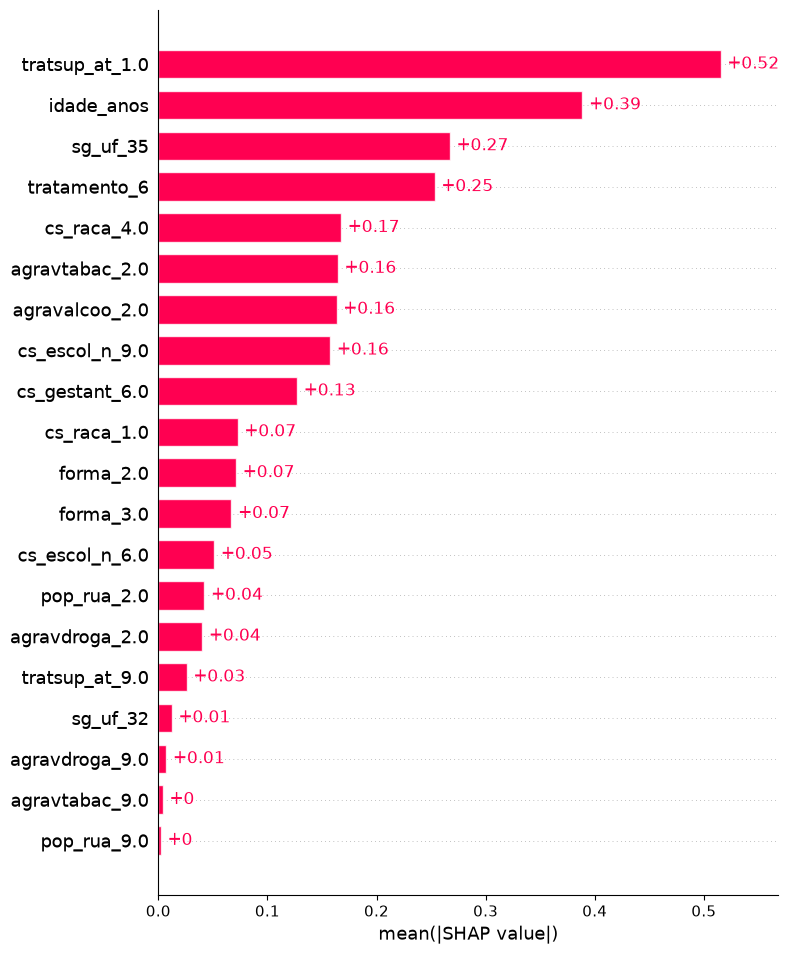

In [19]:
# Importância média das variáveis
shap.plots.bar(shap_values, max_display = None)

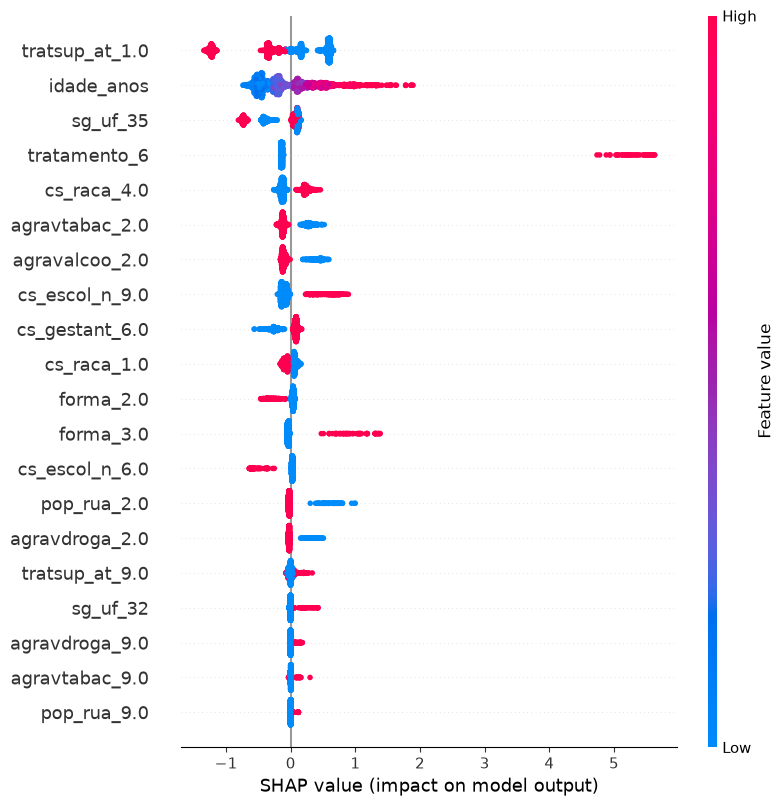

In [20]:
# Beeswarm: mostra a importância e a direção da variável para o desfecho
shap.plots.beeswarm(shap_values, max_display = None)

In [21]:
# Criação do DataFrame auxiliar para selecionar os indivíduos para análise
df_predict = pd.DataFrame(data = {"prob_desfecho": xgb_novo.predict_proba(X_test_novo)[:,1],
                                  "y_test": y_test})
df_predict.head()

,prob_desfecho,y_test
0,0.069692,0.0
1,0.084982,0.0
2,0.165501,0.0
3,0.044578,0.0
4,0.013476,0.0


In [22]:
#Seleção do paciente que foi a óbito, com a maior predição
df_predict.loc[df_predict.y_test == 1].sort_values(by = "prob_desfecho", ascending = False).head()

,prob_desfecho,y_test
1115,0.992664,1.0
1690,0.992581,1.0
1929,0.992099,1.0
1026,0.991861,1.0
1273,0.991704,1.0


In [23]:
#Force Plot
shap.initjs()
shap.force_plot(shap_values[1115])

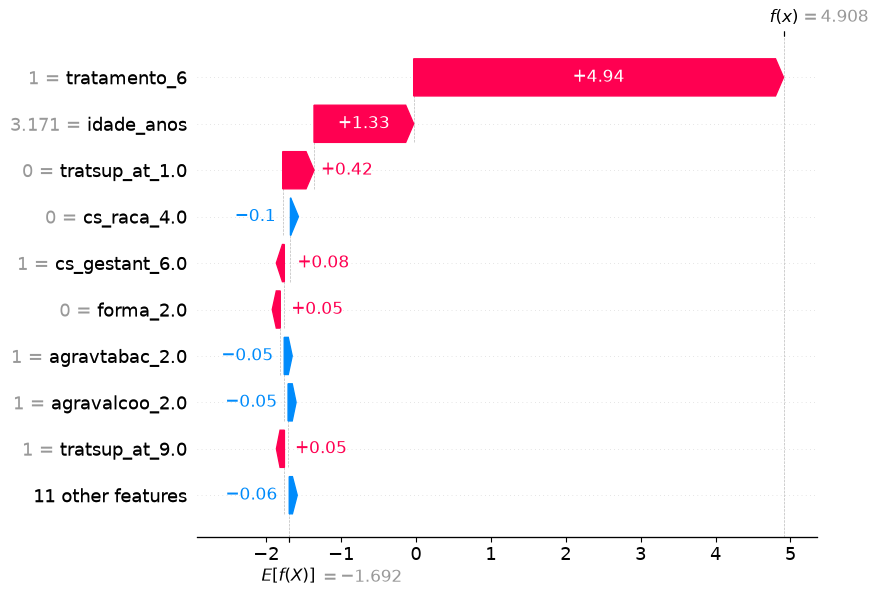

In [24]:
shap.plots.waterfall(shap_values[1115])

In [25]:
df_predict.loc[df_predict.y_test == 1].sort_values(by = "prob_desfecho", ascending = True).head()


,prob_desfecho,y_test
628,0.025506,1.0
1813,0.028017,1.0
1843,0.031973,1.0
2395,0.043184,1.0
612,0.046006,1.0


In [26]:
#Force Plot
shap.initjs()
shap.force_plot(shap_values[628])

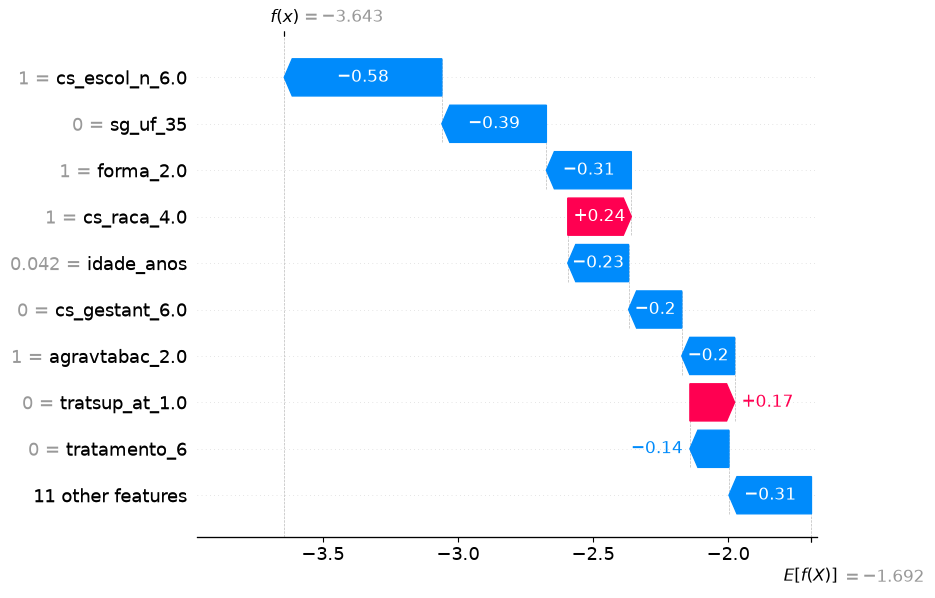

In [27]:
#Waterfall Plot
shap.plots.waterfall(shap_values[628])